In [1]:
import cv2
import albumentations as A
import matplotlib.pyplot as plt

In [2]:
def load_image(path, flags=cv2.IMREAD_COLOR):
    img = cv2.imread(path, flags)
    if img is None:
        raise ValueError(f"Не удалось загрузить изображение: {path}")
    if img.ndim == 3 and img.shape[2] == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return img


image = load_image('sample_image.jpg')
print(image.shape, image.dtype)

(360, 500, 3) uint8


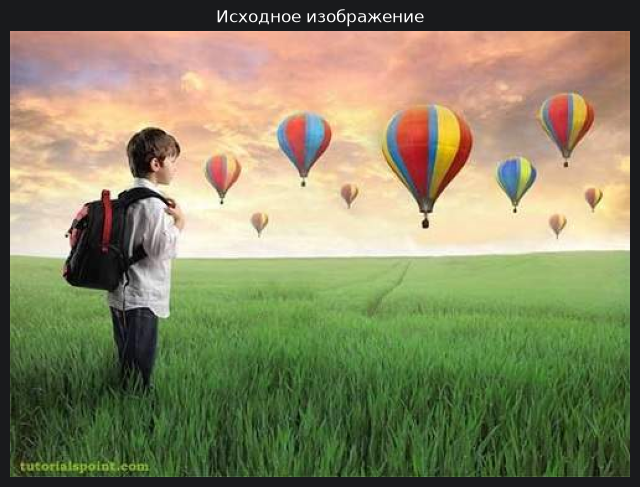

In [3]:
def display_image(image, title=None):
    plt.figure(figsize=(8, 6))
    plt.imshow(image)
    plt.title(title)
    plt.axis('off')
    plt.show()


display_image(image, 'Исходное изображение')

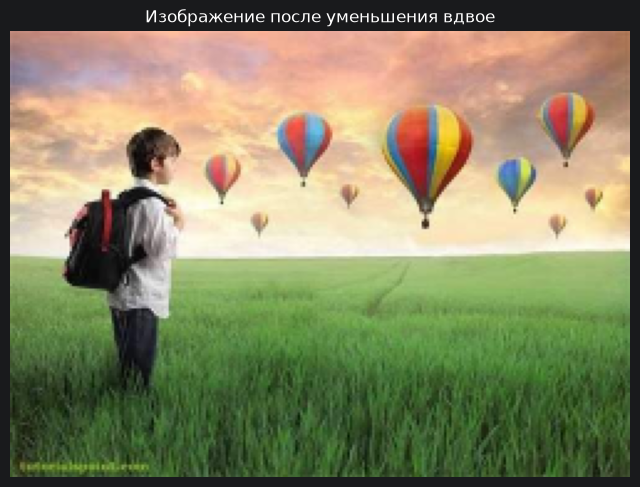

(180, 250, 3)


In [4]:
resized_image = cv2.resize(image, (250, 180), interpolation=cv2.INTER_AREA)
display_image(resized_image, 'Изображение после уменьшения вдвое')
print(resized_image.shape)

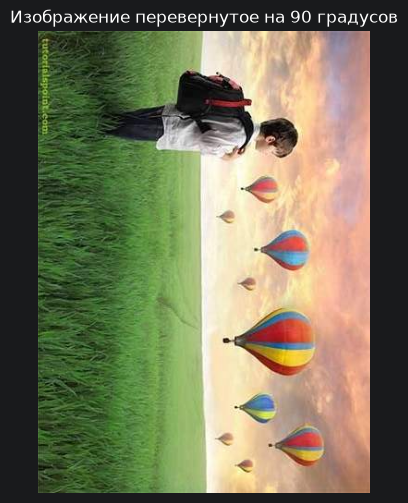

(500, 360, 3)


In [5]:
rotated_image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
display_image(rotated_image, 'Изображение перевернутое на 90 градусов')
print(rotated_image.shape)

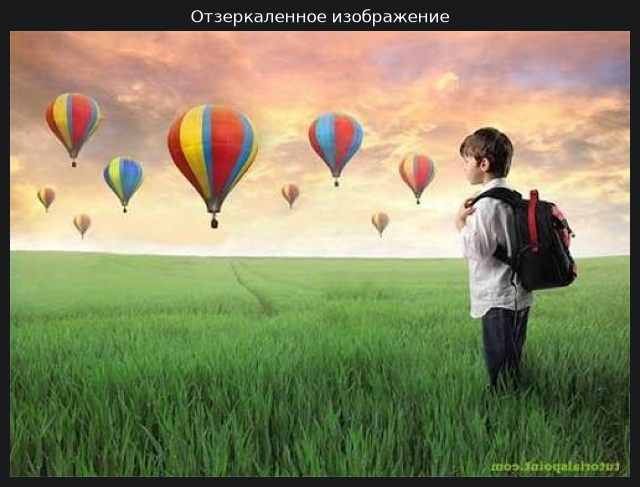

(360, 500, 3)


In [6]:
flipped_image = cv2.flip(image, 1)
display_image(flipped_image, 'Отзеркаленное изображение')
print(flipped_image.shape)

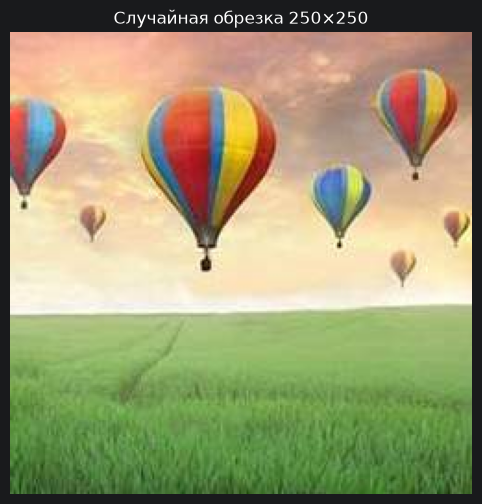

(250, 250, 3)


In [7]:
transform = A.RandomCrop(height=250, width=250, p=1.0)
transformed_image = transform(image=image)['image']
display_image(transformed_image, 'Случайная обрезка 250×250')
print(transformed_image.shape)

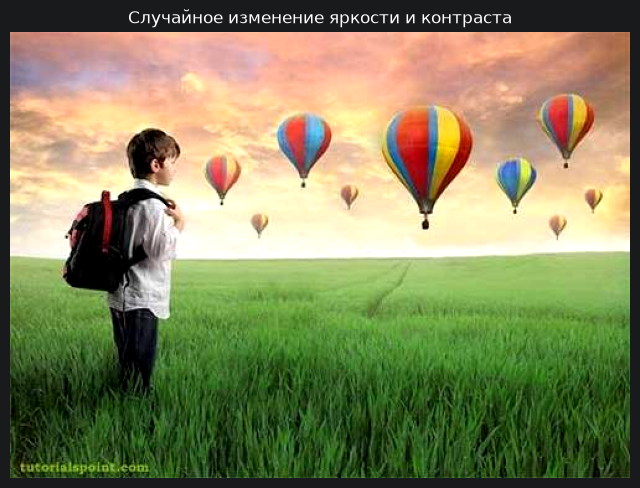

(360, 500, 3)


In [8]:
transform = A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=1.0)
brightness_image = transform(image=image)['image']
display_image(brightness_image, 'Случайное изменение яркости и контраста')
print(brightness_image.shape)

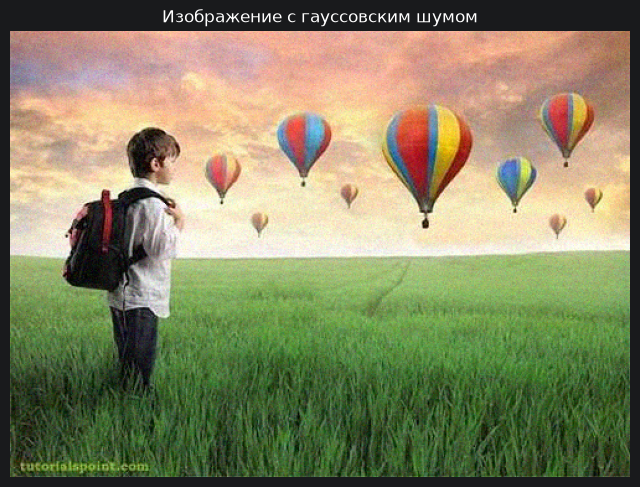

(360, 500, 3)


In [9]:
transform = A.GaussNoise(std_range=(0.03, 0.08), p=1.0)
noise_image = transform(image=image)['image']
display_image(noise_image, 'Изображение с гауссовским шумом')
print(noise_image.shape)

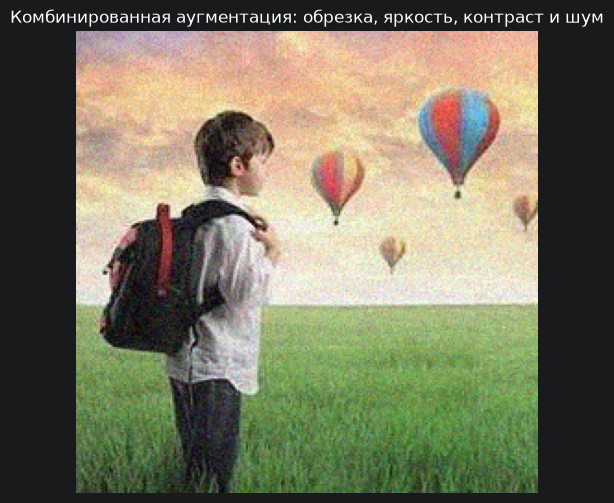

(250, 250, 3)


In [10]:
def augment_image(image):
    transform = A.Compose([
        A.RandomCrop(height=250, width=250, p=1.0),
        A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=1.0),
        A.GaussNoise(std_range=(0.03, 0.08), p=1.0)
    ])
    return transform(image=image)['image']


augmented_image = augment_image(image=image)
display_image(augmented_image, 'Комбинированная аугментация: обрезка, яркость, контраст и шум')
print(augmented_image.shape)

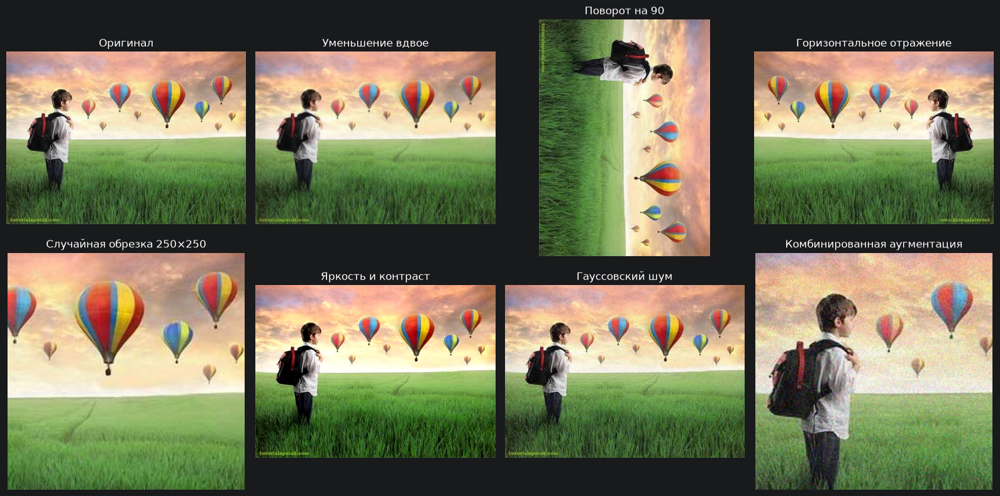

In [11]:
fig, ax = plt.subplots(2, 4, figsize=(16, 8))

ax[0, 0].imshow(image)
ax[0, 0].set_title('Оригинал')
ax[0, 0].axis('off')

ax[0, 1].imshow(resized_image)
ax[0, 1].set_title('Уменьшение вдвое')
ax[0, 1].axis('off')

ax[0, 2].imshow(rotated_image)
ax[0, 2].set_title('Поворот на 90')
ax[0, 2].axis('off')

ax[0, 3].imshow(flipped_image)
ax[0, 3].set_title('Горизонтальное отражение')
ax[0, 3].axis('off')

ax[1, 0].imshow(transformed_image)
ax[1, 0].set_title('Случайная обрезка 250×250')
ax[1, 0].axis('off')

ax[1, 1].imshow(brightness_image)
ax[1, 1].set_title('Яркость и контраст')
ax[1, 1].axis('off')

ax[1, 2].imshow(noise_image)
ax[1, 2].set_title('Гауссовский шум')
ax[1, 2].axis('off')

ax[1, 3].imshow(augmented_image)
ax[1, 3].set_title('Комбинированная аугментация')
ax[1, 3].axis('off')

plt.tight_layout()
plt.show()

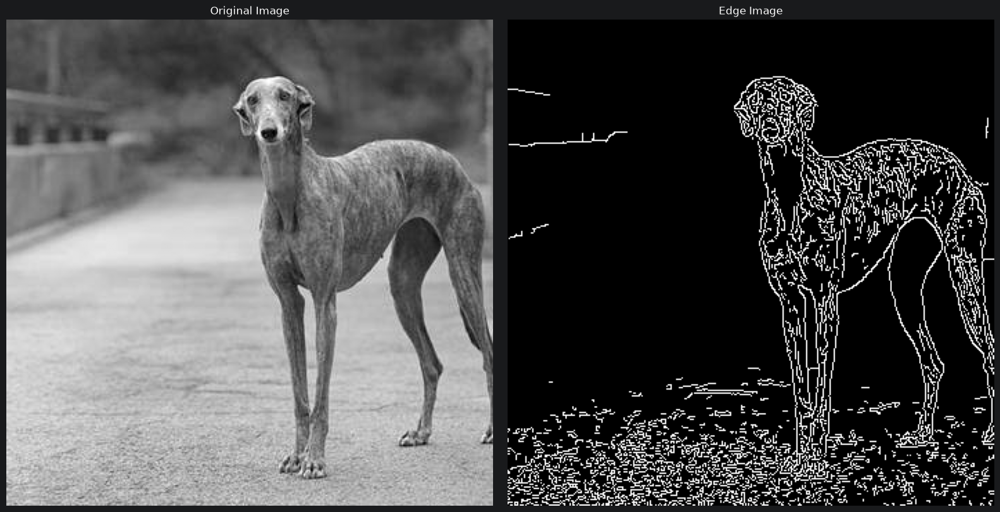

In [12]:
# Возьму для выделения границ другой пример
image2 = load_image('images.jpg', cv2.IMREAD_GRAYSCALE)
edges = cv2.Canny(image2, 100, 150, apertureSize=3)

fig, ax = plt.subplots(1, 2, figsize=(16, 8))

ax[0].imshow(image2, cmap='gray')
ax[0].set_title('Original Image')
ax[0].axis('off')

ax[1].imshow(edges, cmap='gray')
ax[1].set_title('Edge Image')
ax[1].axis('off')

plt.tight_layout()
plt.show()

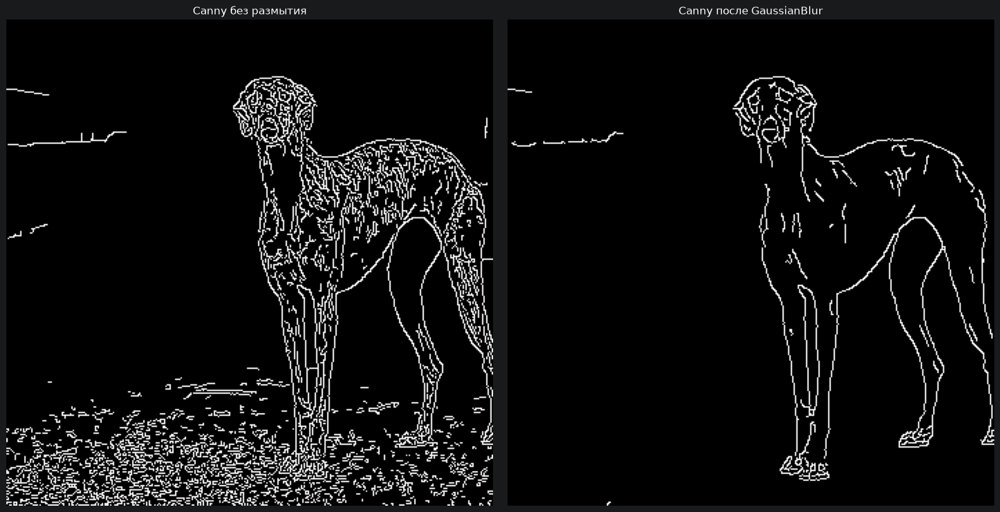

In [13]:
# Вижу что много линий от текстур дорожек и шерсти
# Сравню до и после размытия GaussianBlur
blurred_image = cv2.GaussianBlur(image2, (5, 5), sigmaX=0)
blurred_edges = cv2.Canny(blurred_image, 100, 150, apertureSize=3)

fig, ax = plt.subplots(1, 2, figsize=(16, 8))

ax[0].imshow(edges, cmap='gray')
ax[0].set_title('Canny без размытия')
ax[0].axis('off')

ax[1].imshow(blurred_edges, cmap='gray')
ax[1].set_title('Canny после GaussianBlur')
ax[1].axis('off')

plt.tight_layout()
plt.show()

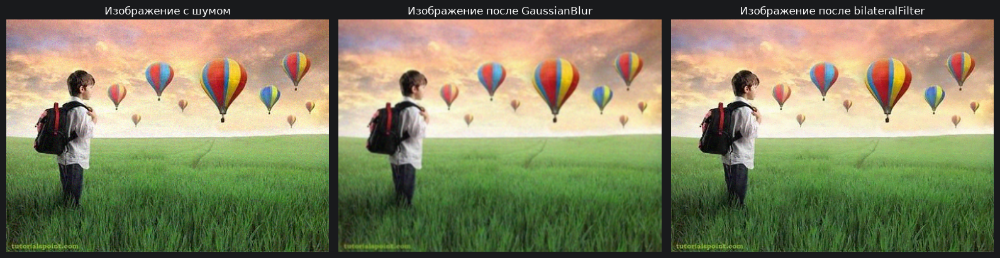

In [14]:
# Теперь возьмем наш noise_image, хочу его обработать GaussianBlur и bilateralFilter
# Сравню где меньше зернистости и где лучше сохранились границы объектов
blurred_image2 = cv2.GaussianBlur(noise_image, (5, 5), sigmaX=0)
bilateral_image = cv2.bilateralFilter(noise_image, d=9, sigmaColor=15, sigmaSpace=15)

fig, ax = plt.subplots(1, 3, figsize=(16, 8))

ax[0].imshow(noise_image)
ax[0].set_title('Изображение с шумом')
ax[0].axis('off')

ax[1].imshow(blurred_image2)
ax[1].set_title('Изображение после GaussianBlur')
ax[1].axis('off')

ax[2].imshow(bilateral_image)
ax[2].set_title('Изображение после bilateralFilter')
ax[2].axis('off')

plt.tight_layout()
plt.show()

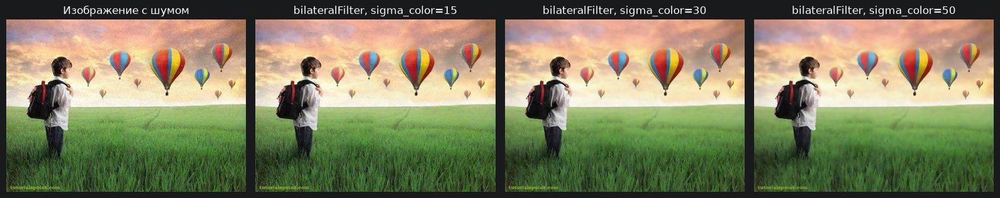

In [15]:
# GaussianBlur заметно убрал зернистость, но размыл детали человека, шаров и травы
# bilateralFilter сохранил больше деталей, но оставил много шума
# Теперь буду подбирать sigmaColor
sigma_color_list = [15, 30, 50]

fig, ax = plt.subplots(1, 4, figsize=(16, 8))

ax[0].imshow(noise_image)
ax[0].set_title('Изображение с шумом')
ax[0].axis('off')

for i, sigma_color in enumerate(sigma_color_list, start=1):
    filtered = cv2.bilateralFilter(noise_image, d=9, sigmaColor=sigma_color, sigmaSpace=15)

    ax[i].imshow(filtered)
    ax[i].set_title(f'bilateralFilter, sigma_color={sigma_color}')
    ax[i].axis('off')

plt.tight_layout()
plt.show()
# При 15 осталось много зернистости, 30 шум уменьшился и детали хорошо видны
# 50 уже очень гладкое, больше всего видно на траве, очень сглаженная

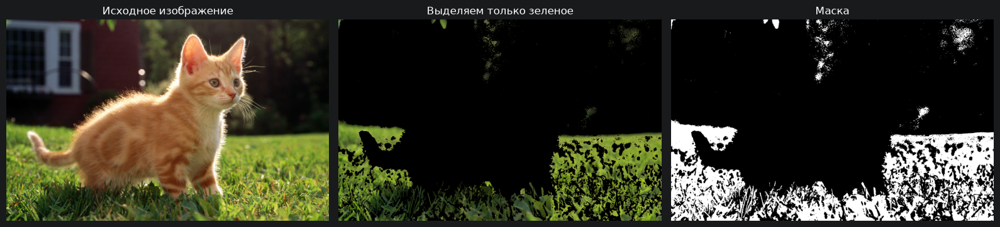

In [16]:
# Для следующего примера снова возьму новое изображение, а именно будем выделять отдельно зеленый цвет и его покажем
# с помощью cv2.inRange, предварительно переведя изображение в hsv
image3 = load_image('0a19729c.jpg')
hsv = cv2.cvtColor(image3, cv2.COLOR_RGB2HSV)
mask = cv2.inRange(hsv, (35, 40, 40), (85, 255, 255))
green_image = cv2.bitwise_and(image3, image3, mask=mask)

fig, ax = plt.subplots(1, 3, figsize=(16, 8))

ax[0].imshow(image3)
ax[0].set_title('Исходное изображение')
ax[0].axis('off')

ax[1].imshow(green_image)
ax[1].set_title('Выделяем только зеленое')
ax[1].axis('off')

ax[2].imshow(mask, cmap='gray')
ax[2].set_title('Маска')
ax[2].axis('off')

plt.tight_layout()
plt.show()